# The edge lab

Companion to `docs/`. Every claim in the report that can be computed is computed here, so you can change an
assumption and watch the conclusion move.

**Plan**

| cell | what it shows | doc |
|---|---|---|
| 2 | setup | — |
| 3 | the fundamental law: IC × √breadth, six configurations | 01 §4 |
| 4 | the same thing simulated — and the effective-breadth correction | 01 §4 |
| 5 | IC decay curves → optimal holding period | 02 §2, 03 §3.5 |
| 6 | multiple testing: the t-hurdle and the deflated Sharpe ratio | 02 §1 |
| 7 | overfitting demo: 1,000 random signals, and why the best one is worthless | 03 §1 |
| 8 | capacity: square-root impact, capacity curve, breakeven AUM | 02 §4 |
| 9 | decay: fitting half-lives, and the half-life of a *blend* | 03 §3 |
| 10 | what an edge is worth: discounting a decaying alpha stream | 03 §3.4 |
| 11 | sizing: fractional Kelly, estimation error, and skew | 02 §7 |
| 12 | summary of the numbers | — |

Run all: it takes a few seconds. Everything is seeded, so the numbers are reproducible.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

np.random.seed(7)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams.update({"figure.figsize": (8, 3.6), "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False})

TRADING_DAYS = 252
print("numpy", np.__version__, "| pandas", pd.__version__)


numpy 2.2.4 | pandas 2.2.3


In [2]:
def br_eff(n_names, n_periods, rho):
    """Effective number of independent bets per year for a cross-section of n_names,
    rebalanced n_periods times a year, with average pairwise correlation rho between bets."""
    return n_periods * n_names / (1 + (n_names - 1) * rho)

rows = [
    # label,                                IC,  names, rebal/yr, rho, TC
    ("500 names, monthly, independent",    0.04, 500, 12, 0.00, 1.0),
    ("500 names, monthly, rho=0.03",       0.04, 500, 12, 0.03, 1.0),
    ("500 names, monthly, rho=0.15",       0.04, 500, 12, 0.15, 1.0),
    ("40 names long-only, monthly",        0.04,  40, 12, 0.00, 0.5),
    ("15 futures, weekly trend",           0.06,  15, 52, 0.00, 0.8),
    ("3 macro trades a year",              0.15,   3,  1, 0.00, 0.9),
]
tbl = pd.DataFrame(
    [(lab, ic, names, ry, rho, tc, br_eff(names, ry, rho),
      tc * ic * np.sqrt(br_eff(names, ry, rho)))
     for lab, ic, names, ry, rho, tc in rows],
    columns=["setting", "IC", "names", "rebal/yr", "rho", "TC", "BR_eff", "IR"])
tbl.round(3)


,setting,IC,names,rebal/yr,rho,TC,BR_eff,IR
0,"500 names, monthly, independent",0.0400,500,12,0.0000,1.0000,"6,000.0000",3.0980
1,"500 names, monthly, rho=0.03",0.0400,500,12,0.0300,1.0000,375.7040,0.7750
2,"500 names, monthly, rho=0.15",0.0400,500,12,0.1500,1.0000,79.1030,0.3560
3,"40 names long-only, monthly",0.0400,40,12,0.0000,0.5000,480.0000,0.4380
4,"15 futures, weekly trend",0.0600,15,52,0.0000,0.8000,780.0000,1.3410
5,3 macro trades a year,0.1500,3,1,0.0000,0.9000,3.0000,0.2340


   rho  simulated IR  formula IR  IR if you'd believed 500 independent bets
0.0000        3.0900      3.1000                                     3.1000
0.0300        0.7500      0.7800                                     3.1000
0.1000        0.4400      0.4300                                     3.1000
0.1500        0.3700      0.3600                                     3.1000
0.3000        0.2700      0.2500                                     3.1000
0.5000        0.2200      0.2000                                     3.1000


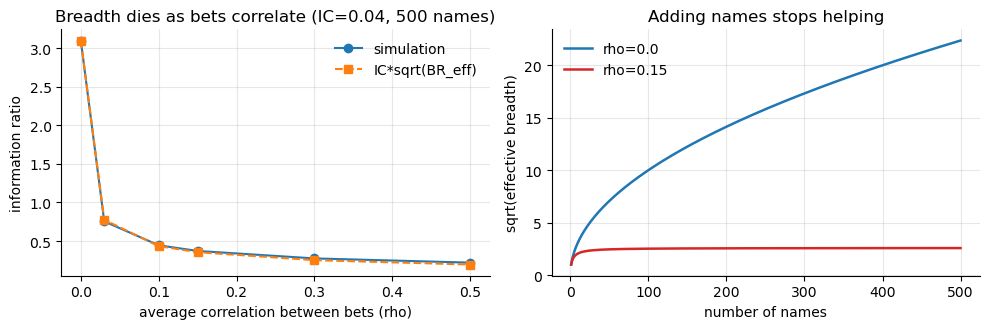

In [3]:
def simulate_ir(ic, n_names, n_periods, rho, trials=300, periods_per_year=12):
    """Each bet pays ic on average with unit volatility; bets are equicorrelated with rho.
    Portfolio = equally weighted average of the n_names bets, rebalanced n_periods times.
    Returns the annualised information ratio of that portfolio."""
    out = []
    for _ in range(trials):
        f = np.random.randn(n_periods, 1)
        e = np.random.randn(n_periods, n_names)
        noise = np.sqrt(rho) * f + np.sqrt(1 - rho) * e     # unit variance: rho + (1-rho) = 1
        port = (ic + noise).mean(axis=1)                    # equally weighted across names
        out.append(port.mean() / port.std() * np.sqrt(periods_per_year))
    return np.mean(out)

rhos = [0.0, 0.03, 0.10, 0.15, 0.30, 0.50]
sim = [simulate_ir(0.04, 500, 240, r) for r in rhos]
theory = [0.04 * np.sqrt(br_eff(500, 12, r)) for r in rhos]

cmp = pd.DataFrame({"rho": rhos, "simulated IR": sim, "formula IR": theory,
                    "IR if you'd believed 500 independent bets": 0.04 * np.sqrt(500 * 12)})
print(cmp.round(2).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(cmp.rho, cmp["simulated IR"], "o-", label="simulation")
ax[0].plot(cmp.rho, cmp["formula IR"], "s--", label="IC*sqrt(BR_eff)")
ax[0].set_xlabel("average correlation between bets (rho)")
ax[0].set_ylabel("information ratio")
ax[0].set_title("Breadth dies as bets correlate (IC=0.04, 500 names)")
ax[0].legend(frameon=False)

for rr, c in zip([0.0, 0.15], ["C0", "C3"]):
    n = np.arange(1, 501)
    ax[1].plot(n, np.sqrt(n / (1 + (n - 1) * rr)), color=c, label=f"rho={rr}", lw=1.8)
ax[1].set_xlabel("number of names")
ax[1].set_ylabel("sqrt(effective breadth)")
ax[1].set_title("Adding names stops helping")
ax[1].legend(frameon=False)
plt.tight_layout(); plt.show()


 signal horizon k* (days)  IC_max  best H* (days)  H*/k*  net alpha at H*  net alpha if you trade daily
                        3  0.0300               2 0.6670           0.0650                        0.0530
                        3  0.0600               2 0.6670           0.1370                        0.1130
                       10  0.0300               6 0.6000           0.0310                        0.0080
                       10  0.0600               7 0.7000           0.0700                        0.0220
                       21  0.0300              14 0.6670           0.0180                       -0.0010
                       21  0.0600              14 0.6670           0.0450                        0.0040
                       63  0.0300              51 0.8100           0.0080                       -0.0050
                       63  0.0600              46 0.7300           0.0230                       -0.0040


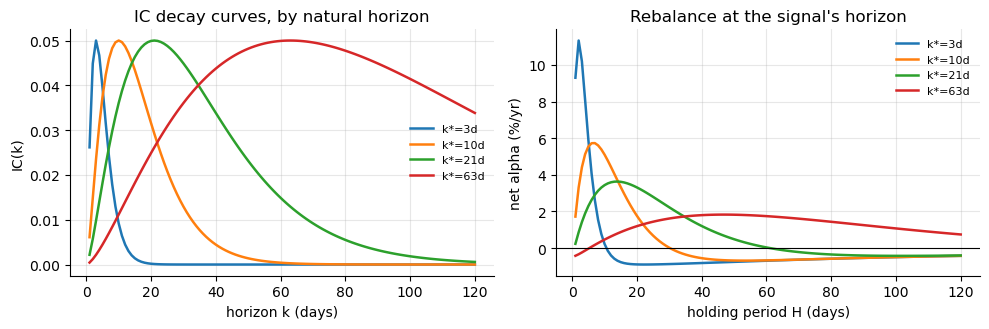

In [4]:
# --- D1: horizon decay, and the holding period it implies -------------------
# A signal with a "natural horizon" k*: predictive power builds, peaks around k*, then fades.
#   IC(k) = ic_max * (k/k*)^a * exp(a*(1 - k/k*))     a = how sharply it peaks
# Hold H days, rebalance every H days:
#   gross alpha/yr = (252/H) * IC(H) * sigma_cs * sqrt(H)      (IC paid on H days of risk)
#   cost/yr        = (252/H) * [ tau*spread + tau*Y*sigma_d*sqrt(tau*q) ]
#       tau     = 1 - rho**H   fraction of the book replaced (rho = daily signal persistence)
#       q       = portfolio position as a fraction of ADV  -> the sqrt impact term
# Note what falling H does: more breadth, more turnover, more impact per trade (bigger clips).

def ic_curve(k, ic_max, kstar, a=1.5):
    x = k / kstar
    return ic_max * x**a * np.exp(a * (1 - x))

def net_alpha(H, ic_max, kstar, rho=0.97, sigma_cs=0.015, sigma_d=0.02,
              spread=0.0005, Y=0.8, q=0.01):
    ic = ic_curve(H, ic_max, kstar)
    tau = 1 - rho**H
    gross = (252 / H) * ic * sigma_cs * np.sqrt(H)
    cost = (252 / H) * (tau * spread + tau * Y * sigma_d * np.sqrt(tau * q))
    return gross - cost, gross, cost

Hs = np.arange(1, 121)
rows = []
for kstar in [3, 10, 21, 63]:
    for ic_max in [0.03, 0.06]:
        vals = [net_alpha(H, ic_max, kstar)[0] for H in Hs]
        i = int(np.argmax(vals))
        rows.append((kstar, ic_max, Hs[i], Hs[i] / kstar, vals[i], vals[0]))
opt = pd.DataFrame(rows, columns=["signal horizon k* (days)", "IC_max", "best H* (days)",
                                  "H*/k*", "net alpha at H*", "net alpha if you trade daily"])
print(opt.round(3).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
k = np.arange(1, 121)
for kstar in [3, 10, 21, 63]:
    ax[0].plot(k, ic_curve(k, 0.05, kstar), lw=1.8, label=f"k*={kstar}d")
ax[0].set_xlabel("horizon k (days)"); ax[0].set_ylabel("IC(k)")
ax[0].set_title("IC decay curves, by natural horizon"); ax[0].legend(frameon=False, fontsize=8)

for kstar in [3, 10, 21, 63]:
    ax[1].plot(Hs, [net_alpha(H, 0.05, kstar)[0] * 100 for H in Hs], lw=1.8, label=f"k*={kstar}d")
ax[1].axhline(0, color="k", lw=.8)
ax[1].set_xlabel("holding period H (days)"); ax[1].set_ylabel("net alpha (%/yr)")
ax[1].set_title("Rebalance at the signal's horizon")
ax[1].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()


Five years of daily data. What a Sharpe ratio has to be before it means anything:

 trials N  expected max SR of pure noise (ann.)  equivalent t-stat  SR (ann.) needed for DSR>0.95
        1                                0.0000             0.0000                         0.7400
       10                                0.7000             1.5800                         1.4400
       50                                1.0200             2.2800                         1.7500
      100                                1.1300             2.5300                         1.8700
      500                                1.3700             3.0500                         2.1000
     1000                                1.4600             3.2600                         2.1900
    10000                                1.7300             3.8600                         2.4600

Your backtest says Sharpe 1.5 over 5 years. Probability it is real, by how many things you tried:
       1 trials -> 100.0%
      10

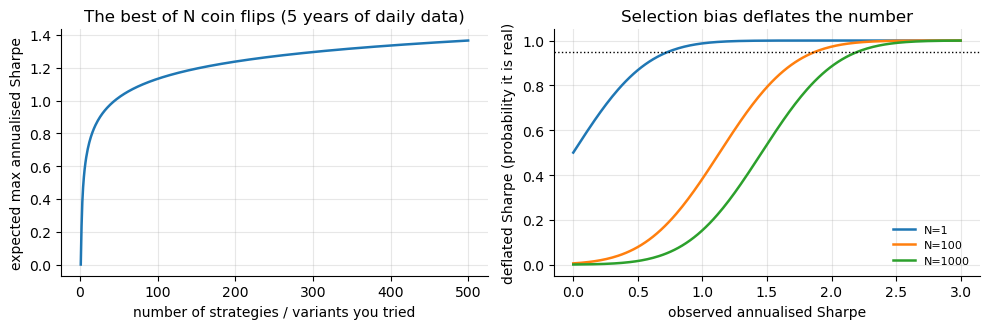

In [5]:
# --- multiple testing: the hurdle a Sharpe has to clear --------------------
# Bailey & Lopez de Prado (2014), "The Deflated Sharpe Ratio".
# SR here is per-observation (daily); annualise at the end.

EULER = 0.5772156649

def sr_std(T, sr=0.0, skew=0.0, kurt=3.0):
    """Standard deviation of the estimated Sharpe ratio across T observations."""
    return np.sqrt((1 - skew * sr + (kurt - 1) / 4 * sr ** 2) / (T - 1))

def expected_max_sr(N, T, sr=0.0):
    """Expected maximum of N independent zero-skill Sharpe estimates (0 if you only tried once)."""
    if N <= 1:
        return 0.0
    s = sr_std(T, sr)
    return s * ((1 - EULER) * stats.norm.ppf(1 - 1 / N) + EULER * stats.norm.ppf(1 - 1 / (N * np.e)))

def deflated_sr(sr, N, T, skew=0.0, kurt=3.0):
    """Probability that the true SR exceeds what the best of N zero-skill trials would produce."""
    sr0 = expected_max_sr(N, T, sr)
    return stats.norm.cdf((sr - sr0) * np.sqrt(T - 1) / np.sqrt(1 - skew * sr + (kurt - 1) / 4 * sr ** 2))

T = 5 * TRADING_DAYS              # five years of daily observations
Ns = [1, 10, 50, 100, 500, 1000, 10000]

tab = pd.DataFrame({
    "trials N": Ns,
    "expected max SR of pure noise (ann.)": [expected_max_sr(n, T) * np.sqrt(TRADING_DAYS) for n in Ns],
    "equivalent t-stat": [expected_max_sr(n, T) * np.sqrt(T) for n in Ns],
    "SR (ann.) needed for DSR>0.95": [
        (expected_max_sr(n, T) + 1.645 * sr_std(T)) * np.sqrt(TRADING_DAYS) for n in Ns],
})
print("Five years of daily data. What a Sharpe ratio has to be before it means anything:\n")
print(tab.round(2).to_string(index=False))

print("\nYour backtest says Sharpe 1.5 over 5 years. Probability it is real, by how many things you tried:")
for n in Ns:
    print(f"  {n:>6} trials -> {deflated_sr(1.5 / np.sqrt(TRADING_DAYS), n, T):6.1%}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
grid = np.arange(1, 501)
ax[0].plot(grid, [expected_max_sr(n, T) * np.sqrt(TRADING_DAYS) for n in grid], lw=1.8)
ax[0].set_xlabel("number of strategies / variants you tried")
ax[0].set_ylabel("expected max annualised Sharpe")
ax[0].set_title("The best of N coin flips (5 years of daily data)")

srs = np.linspace(0, 3, 200) / np.sqrt(TRADING_DAYS)
for n, c in zip([1, 100, 1000], ["C0", "C1", "C2"]):
    ax[1].plot(srs * np.sqrt(TRADING_DAYS), [deflated_sr(s, n, T) for s in srs], lw=1.8, label=f"N={n}")
ax[1].axhline(0.95, ls=":", color="k", lw=1)
ax[1].set_xlabel("observed annualised Sharpe"); ax[1].set_ylabel("deflated Sharpe (probability it is real)")
ax[1].set_title("Selection bias deflates the number")
ax[1].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()


signals tested:            1000, every one of them pure noise
best in-sample Sharpe:     1.33   (t-stat 2.97 over 5 years)
the same signal out-of-sample: 0.20
average out-of-sample Sharpe across all: 0.01 (sd 0.47)
correlation between in-sample and out-of-sample Sharpe: 0.02
share of 'signals' with a positive OOS Sharpe: 52%


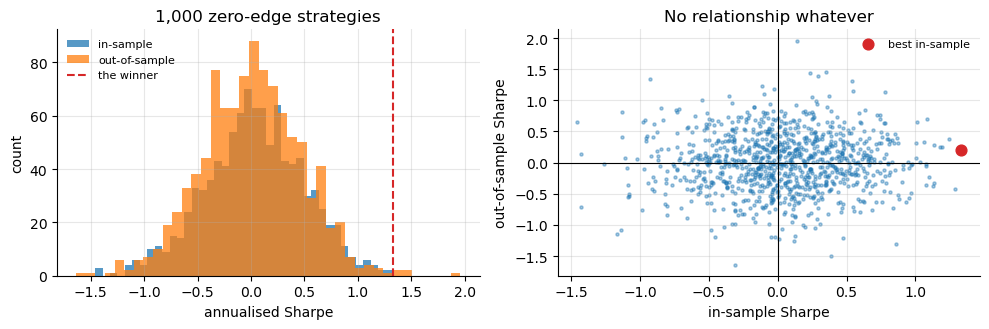

In [6]:
# --- the zoo, simulated: 1,000 signals with ZERO predictive power -----------
# 200 stocks, 120 months of returns. Every signal is pure noise, independent of returns.
# We rank each signal, go long the top half / short the bottom half, and look at the best one.

rng = np.random.default_rng(11)
T, N_stocks, N_signals = 120, 200, 1000
R = rng.standard_normal((T, N_stocks))          # monthly returns, iid, no structure
half = T // 2

def strat_returns(signal, rets):
    """Dollar-neutral rank weights from the signal, applied to next month's returns."""
    ranks = stats.rankdata(signal, axis=1)
    w = (ranks - ranks.mean(axis=1, keepdims=True)) / N_stocks
    return (w * rets).sum(axis=1) * N_stocks / (N_stocks / 4)   # scale to a sensible vol

is_sr, oos_sr = [], []
for j in range(N_signals):
    S = rng.standard_normal((T, N_stocks))      # pure noise: no relation to R whatsoever
    r = strat_returns(S, R)
    is_sr.append(r[:half].mean() / r[:half].std() * np.sqrt(12))
    oos_sr.append(r[half:].mean() / r[half:].std() * np.sqrt(12))

is_sr, oos_sr = np.array(is_sr), np.array(oos_sr)
best = int(np.argmax(is_sr))

print(f"signals tested:            {N_signals}, every one of them pure noise")
print(f"best in-sample Sharpe:     {is_sr[best]:.2f}   (t-stat {is_sr[best]*np.sqrt(60/12):.2f} over 5 years)")
print(f"the same signal out-of-sample: {oos_sr[best]:.2f}")
print(f"average out-of-sample Sharpe across all: {oos_sr.mean():.2f} (sd {oos_sr.std():.2f})")
print(f"correlation between in-sample and out-of-sample Sharpe: {np.corrcoef(is_sr, oos_sr)[0,1]:.2f}")
print(f"share of 'signals' with a positive OOS Sharpe: {(oos_sr > 0).mean():.0%}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].hist(is_sr, bins=40, alpha=.75, label="in-sample")
ax[0].hist(oos_sr, bins=40, alpha=.75, label="out-of-sample")
ax[0].axvline(is_sr[best], color="C3", ls="--", lw=1.5, label="the winner")
ax[0].set_xlabel("annualised Sharpe"); ax[0].set_ylabel("count")
ax[0].set_title("1,000 zero-edge strategies"); ax[0].legend(frameon=False, fontsize=8)

ax[1].scatter(is_sr, oos_sr, s=5, alpha=.4)
ax[1].scatter(is_sr[best], oos_sr[best], color="C3", s=60, zorder=3, label="best in-sample")
ax[1].axhline(0, color="k", lw=.8); ax[1].axvline(0, color="k", lw=.8)
ax[1].set_xlabel("in-sample Sharpe"); ax[1].set_ylabel("out-of-sample Sharpe")
ax[1].set_title("No relationship whatever")
ax[1].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()


base: a=4%/yr, H=21d         capacity = $      78m   (net alpha at $100m: -0.44%/yr)
alpha x2                     capacity = $     371m   (net alpha at $100m:  3.56%/yr)
holding x2                   capacity = $     371m   (net alpha at $100m:  1.78%/yr)
alpha x2 and holding x2      capacity = $   1,608m   (net alpha at $100m:  5.78%/yr)
thin liquidity (ADV 10m)     capacity = $      16m   (net alpha at $100m: -5.19%/yr)
fast (H=5d)                  capacity = $       1m   (net alpha at $100m: -14.65%/yr)


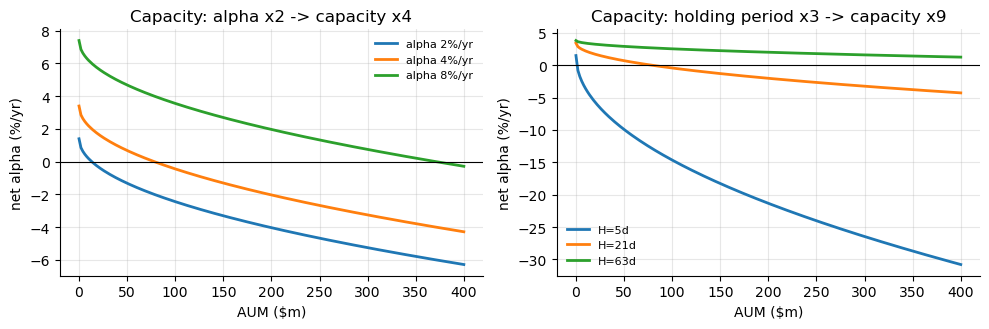

In [7]:
# --- capacity: the square-root law sets the ceiling ------------------------
# alpha per name per year a, holding H days, one-way spread s, impact Y*sigma_d*sqrt(q),
# q = position / ADV, w = weight per name, M names.
#   net alpha(AUM) = a - (252/H) * [ s + 2*Y*sigma_d*sqrt(AUM*w/ADV) ]
#   => AUM* = (ADV/w) * [ (a*H/252 - s) / (2*Y*sigma_d) ]**2        at net alpha = 0

def net_alpha_capacity(aum, a, H, adv=50e6, s=0.0005, Y=0.8, sigma_d=0.02, w=1/200):
    return a - (252 / H) * (s + 2 * Y * sigma_d * np.sqrt(aum * w / adv))

def capacity(a, H, adv=50e6, s=0.0005, Y=0.8, sigma_d=0.02, w=1/200):
    inner = (a * H / 252 - s) / (2 * Y * sigma_d)
    return (adv / w) * inner ** 2 if inner > 0 else 0.0

base = dict(a=0.04, H=21)
for label, kw in [("base: a=4%/yr, H=21d", {}),
                  ("alpha x2", dict(a=0.08)),
                  ("holding x2", dict(H=42)),
                  ("alpha x2 and holding x2", dict(a=0.08, H=42)),
                  ("thin liquidity (ADV 10m)", dict(adv=10e6)),
                  ("fast (H=5d)", dict(H=5))]:
    p = {**base, **kw}
    print(f"{label:28s} capacity = ${capacity(**p)/1e6:8,.0f}m   "
          f"(net alpha at $100m: {net_alpha_capacity(1e8, **p)*100:5.2f}%/yr)")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
aums = np.linspace(0, 400e6, 200)
for a, c in zip([0.02, 0.04, 0.08], ["C0", "C1", "C2"]):
    ax[0].plot(aums / 1e6, net_alpha_capacity(aums, a, 21) * 100, lw=2, color=c, label=f"alpha {a:.0%}/yr")
ax[0].axhline(0, color="k", lw=.8)
ax[0].set_xlabel("AUM ($m)"); ax[0].set_ylabel("net alpha (%/yr)")
ax[0].set_title("Capacity: alpha x2 -> capacity x4"); ax[0].legend(frameon=False, fontsize=8)

for H, c in zip([5, 21, 63], ["C0", "C1", "C2"]):
    ax[1].plot(aums / 1e6, net_alpha_capacity(aums, 0.04, H) * 100, lw=2, color=c, label=f"H={H}d")
ax[1].axhline(0, color="k", lw=.8)
ax[1].set_xlabel("AUM ($m)"); ax[1].set_ylabel("net alpha (%/yr)")
ax[1].set_title("Capacity: holding period x3 -> capacity x9"); ax[1].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()


true half-life                : 6.00 years
exponential fit -> half-life  : 6.31 years  (one-sided: 95% CI roughly 4.6-8.6)
hyperbolic  fit -> half-life  : 1.46 years
where do the two models disagree most? 10 years out, exponential says 0.0409, hyperbolic says 0.0140

single-strategy half-lives (years): [ 2.3  3.5  6.9 13.9]
half-life of the equal-weighted blend: 4.9 years
alpha left after 10y, blend vs fastest alone: 29.0% vs 5.0%


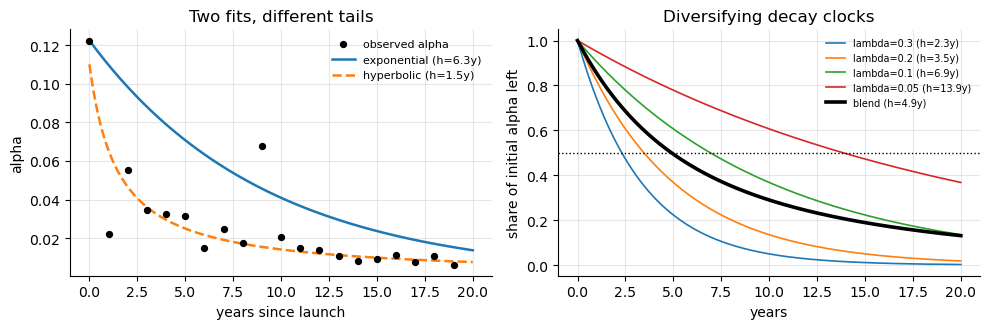

In [8]:
# --- D2: fitting decay, and the half-life of a blend -----------------------
# (a) recover a half-life from a noisy alpha series
true_h = 6.0
lam = np.log(2) / true_h
years = np.arange(0, 20)
rng = np.random.default_rng(3)
alpha = 0.06 * np.exp(-lam * years) * np.exp(rng.normal(0, 0.35, years.size))  # multiplicative noise

# exponential fit: regress log(alpha) on t
slope, intercept, r, p, se = stats.linregress(years, np.log(alpha))
h_exp = -np.log(2) / slope
# hyperbolic fit alpha = a/(1+t/h), fitted numerically on alpha directly
from scipy.optimize import curve_fit
def hyp(t, a, h):  return a / (1 + t / h)
(a_hat, h_hyp), _ = curve_fit(hyp, years, alpha, p0=[alpha[0], 5], maxfev=20000)

print(f"true half-life                : {true_h:.2f} years")
print(f"exponential fit -> half-life  : {h_exp:.2f} years  (one-sided: 95% CI roughly "
      f"{h_exp*np.exp(-1.96*se/(-slope)):.1f}-{h_exp*np.exp(1.96*se/(-slope)):.1f})")
print(f"hyperbolic  fit -> half-life  : {h_hyp:.2f} years")
print(f"where do the two models disagree most? 10 years out, exponential says "
      f"{alpha[0]*np.exp(-np.log(2)/h_exp*10):.4f}, hyperbolic says {hyp(10, a_hat, h_hyp):.4f}")

# (b) the half-life of a portfolio of strategies with different decay clocks
def blend_half_life(lams, weights=None, level=0.5):
    w = np.ones(len(lams)) if weights is None else np.asarray(weights)
    def remaining(t):  return (w * np.exp(-np.asarray(lams) * t)).sum() / w.sum()
    lo, hi = 0.0, 200.0
    for _ in range(200):
        mid = (lo + hi) / 2
        lo, hi = (mid, hi) if remaining(mid) > level else (lo, mid)
    return lo

lams = np.array([0.30, 0.20, 0.10, 0.05])          # per year: half-lives 2.3, 3.5, 6.9, 13.9 years
print("\nsingle-strategy half-lives (years):", np.round(np.log(2) / lams, 1))
print(f"half-life of the equal-weighted blend: {blend_half_life(lams):.1f} years")
print(f"alpha left after 10y, blend vs fastest alone: "
      f"{np.exp(-lams*0+0).dot(np.ones(4))/4*0 + (np.exp(-lams*10).mean()):.1%} vs {np.exp(-0.30*10):.1%}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
t = np.linspace(0, 20, 200)
ax[0].scatter(years, alpha, s=18, color="k", label="observed alpha", zorder=3)
ax[0].plot(t, alpha[0]*np.exp(-np.log(2)/h_exp*t), lw=1.8, label=f"exponential (h={h_exp:.1f}y)")
ax[0].plot(t, hyp(t, a_hat, h_hyp), lw=1.8, ls="--", label=f"hyperbolic (h={h_hyp:.1f}y)")
ax[0].set_xlabel("years since launch"); ax[0].set_ylabel("alpha")
ax[0].set_title("Two fits, different tails"); ax[0].legend(frameon=False, fontsize=8)

for i, l in enumerate(lams):
    ax[1].plot(t, np.exp(-l*t), lw=1.2, color=f"C{i}", label=f"lambda={l} (h={np.log(2)/l:.1f}y)")
ax[1].plot(t, np.exp(-lams[:, None]*t).mean(axis=0), lw=2.6, color="k",
           label=f"blend (h={blend_half_life(lams):.1f}y)")
ax[1].axhline(0.5, ls=":", color="k", lw=1)
ax[1].set_xlabel("years"); ax[1].set_ylabel("share of initial alpha left")
ax[1].set_title("Diversifying decay clocks"); ax[1].legend(frameon=False, fontsize=7)
plt.tight_layout(); plt.show()


A 6%/yr alpha discounted at 5%:

half-life of the alpha  PV (% of AUM)  vs 'lasts forever'  PV per 1pp of alpha
               3 years        21.3500              0.1800               3.5600
               5 years        31.8100              0.2700               5.3000
              10 years        50.2900              0.4200               8.3800
              20 years        70.8700              0.5900              11.8100
          never decays       120.0000              1.0000              20.0000

'It lasts forever' overpays by 3.8x when the half-life is 5 years, and by 5.6x when it is 3.


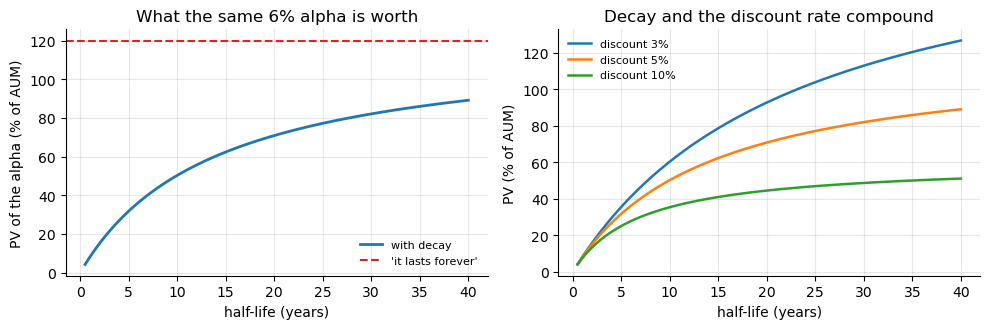

In [9]:
# --- what is a decaying edge worth? ---------------------------------------
# PV of alpha_0 * exp(-lambda t) discounted at r, over T years:
#   PV = alpha_0 * (1 - exp(-(lambda+r)T)) / (lambda + r)
# Compare with the naive "the alpha lasts forever" valuation alpha_0 / r.

def pv(alpha0, half_life_years, r=0.05, T=np.inf):
    lam = np.log(2) / half_life_years
    return alpha0 * (1 - np.exp(-(lam + r) * T)) / (lam + r)

rows = []
for h in [3, 5, 10, 20, np.inf]:
    v = pv(0.06, h) if np.isfinite(h) else 0.06 / 0.05
    rows.append((("never decays" if not np.isfinite(h) else f"{h:.0f} years"),
                 v * 100, v / (0.06 / 0.05), v / 0.06))
val = pd.DataFrame(rows, columns=["half-life of the alpha", "PV (% of AUM)", "vs 'lasts forever'",
                                  "PV per 1pp of alpha"])
print("A 6%/yr alpha discounted at 5%:\n")
print(val.round(2).to_string(index=False))
print(f"\n'It lasts forever' overpays by {(0.06/0.05)/pv(0.06,5):.1f}x when the half-life is 5 years, "
      f"and by {(0.06/0.05)/pv(0.06,3):.1f}x when it is 3.")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
hs = np.linspace(0.5, 40, 200)
ax[0].plot(hs, [pv(0.06, h) * 100 for h in hs], lw=2, label="with decay")
ax[0].axhline(0.06 / 0.05 * 100, ls="--", color="C3", label="'it lasts forever'")
ax[0].set_xlabel("half-life (years)"); ax[0].set_ylabel("PV of the alpha (% of AUM)")
ax[0].set_title("What the same 6% alpha is worth"); ax[0].legend(frameon=False, fontsize=8)

for r, c in zip([0.03, 0.05, 0.10], ["C0", "C1", "C2"]):
    ax[1].plot(hs, [pv(0.06, h, r=r) * 100 for h in hs], lw=1.8, color=c, label=f"discount {r:.0%}")
ax[1].set_xlabel("half-life (years)"); ax[1].set_ylabel("PV (% of AUM)")
ax[1].set_title("Decay and the discount rate compound")
ax[1].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()


(a) mu=8%/yr, sigma=16%/yr -> SR=0.5, full Kelly f*=3.1x, growth at the optimum g*=12.5%/yr, and g=0 at f=6.2x

(b) sizing on 3 years of history, leverage capped at 3x:

                            avg leverage used  mean log growth  5th pctile growth  P(wealth ever halves)
full Kelly on the estimate             2.0620           0.0910            -0.0830                 0.2250
half Kelly                             1.6000           0.0750            -0.0670                 0.1680
quarter Kelly                          0.9340           0.0550            -0.0120                 0.0530
(c) symmetric      median terminal wealth 2.54x | 5th pct 1.72x | median max drawdown -9% | P(dd worse than -50%) 0.0%
(c) negative skew  median terminal wealth 2.46x | 5th pct 1.11x | median max drawdown -24% | P(dd worse than -50%) 2.2%


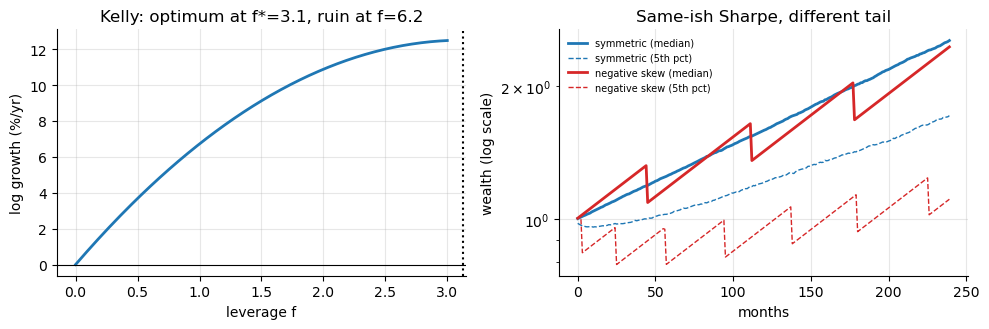

In [10]:
# --- sizing: Kelly, estimation error, and skew ----------------------------
# (a) growth-optimal leverage for a normal edge: g(f) = f*mu - 0.5*f^2*sigma^2, f* = mu/sigma^2
mu, sigma = 0.08, 0.16                      # a good real strategy: SR 0.5, 16% vol
f_star = mu / sigma ** 2
print(f"(a) mu=8%/yr, sigma=16%/yr -> SR={mu/sigma:.1f}, full Kelly f*={f_star:.1f}x, "
      f"growth at the optimum g*={mu**2/(2*sigma**2):.1%}/yr, and g=0 at f={2*f_star:.1f}x")

# (b) what estimation error does to the optimal fraction (3 years of history, leverage capped at 3x)
rng = np.random.default_rng(5)
T_obs_months, n_sims, horizon_years, max_lev = 36, 3000, 10, 3.0
true_mu_m, true_sd_m = mu / 12, sigma / np.sqrt(12)
res = {}
for kappa, label in [(1.0, "full Kelly on the estimate"), (0.5, "half Kelly"), (0.25, "quarter Kelly")]:
    growth, ruin, lev = [], [], []
    for _ in range(n_sims):
        hist = rng.normal(true_mu_m, true_sd_m, T_obs_months)
        mu_hat, sd_hat = hist.mean(), hist.std()
        f = np.clip(kappa * mu_hat / sd_hat ** 2, 0, max_lev)
        lev.append(f)
        r = f * rng.normal(true_mu_m, true_sd_m, horizon_years * 12)
        wealth = np.concatenate([[1.0], np.cumprod(1 + r)])
        growth.append(np.log(max(wealth[-1], 1e-9)) / horizon_years)
        ruin.append(wealth.min() < 0.5)
    res[label] = (np.mean(lev), np.mean(growth), np.percentile(growth, 5), np.mean(ruin))
tab = pd.DataFrame(res, index=["avg leverage used", "mean log growth", "5th pctile growth",
                               "P(wealth ever halves)"]).T
print("\n(b) sizing on 3 years of history, leverage capped at 3x:\n")
print(tab.round(3).to_string())

# (c) same-ish Sharpe, very different skew
def sim_strategy(kind, months=240, n=4000, f=0.5):
    paths = np.empty((n, months))
    for i in range(n):
        if kind == "symmetric":
            r = rng.normal(0.008, 0.030, months)          # ~SR 0.9
        else:                                             # short-vol: small wins, rare -35% months
            r = np.where(rng.random(months) < 0.015, -0.35, 0.0125)
        paths[i] = np.cumprod(1 + f * r)
    return paths

sym, skw = sim_strategy("symmetric"), sim_strategy("short-vol")
for name, p in [("symmetric", sym), ("negative skew", skw)]:
    fin = p[:, -1]
    dd = (p / np.maximum.accumulate(p, axis=1) - 1).min(axis=1)
    print(f"(c) {name:14s} median terminal wealth {np.median(fin):.2f}x | 5th pct {np.percentile(fin,5):.2f}x "
          f"| median max drawdown {np.median(dd):.0%} | P(dd worse than -50%) {(dd < -0.5).mean():.1%}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
fs = np.linspace(0, 3, 200)
ax[0].plot(fs, (fs * mu - 0.5 * fs ** 2 * sigma ** 2) * 100, lw=2)
ax[0].axvline(f_star, ls=":", color="k"); ax[0].axhline(0, color="k", lw=.8)
ax[0].set_xlabel("leverage f"); ax[0].set_ylabel("log growth (%/yr)")
ax[0].set_title(f"Kelly: optimum at f*={f_star:.1f}, ruin at f={2*f_star:.1f}")

for name, p, c in [("symmetric", sym, "C0"), ("negative skew", skw, "C3")]:
    ax[1].plot(np.median(p, axis=0), lw=2, color=c, label=f"{name} (median)")
    ax[1].plot(np.percentile(p, 5, axis=0), lw=1, ls="--", color=c, label=f"{name} (5th pct)")
ax[1].set_yscale("log"); ax[1].set_xlabel("months"); ax[1].set_ylabel("wealth (log scale)")
ax[1].set_title("Same-ish Sharpe, different tail"); ax[1].legend(frameon=False, fontsize=7)
plt.tight_layout(); plt.show()


## What the calculations say

The numbers above, in one place. Every one of them comes from a cell in this notebook; change an assumption
and watch it move.

**1. Breadth is not the number of names.** Grinold's law gives `IR = TC·IC·√BR`. With 500 US stocks
rebalanced monthly and no correlation between bets, an IC of 0.04 buys an IR of 3.1. With a realistic
average pairwise correlation of 0.03 between residual bets it buys **0.78**; at 0.15 it buys **0.36** —
worse than a 40-name long-only portfolio, because of transfer coefficient. The whole art of cross-sectional
investing is pushing ρ̄ down by neutralising factors.

**2. Rebalance at 0.6–0.8× your signal's natural horizon.** Trading daily destroys slow signals: a
21-day-horizon signal worth 1.8%/yr at its optimum is worth −0.1%/yr if rebalanced daily, and the 63-day
one goes to −0.5%/yr. Doubling IC roughly doubles net alpha but barely moves the optimum holding period.

**3. A Sharpe is worth nothing until you divide by the number of things you tried.** Five years of daily
data: the best of 100 zero-skill strategies has an expected Sharpe of **1.13** (t = 2.5); the best of 1,000
has **1.46** (t = 3.26). A backtest Sharpe of 1.5 has a 79% chance of being real after 100 trials, 54%
after 1,000, and 30% after 10,000.

**4. The zoo, simulated.** 1,000 signals with literally zero predictive power: the best shows an in-sample
Sharpe of 1.33 (t = 2.97, "significant") and delivers 0.20 out of sample, with a cross-signal correlation
between in-sample and out-of-sample Sharpe of **0.02**. This is what the factor zoo looks like before
costs and publication bias, and it is why Chen & Velikov find 4bp/month net.

**5. Capacity scales with alpha² and holding period².** Same signal: $78m at 4%/yr and 21 days, $371m at
8%/yr or at 42 days, $1m at a 5-day holding period. Liquidity, not IQ, sets the ceiling.

**6. Decay, measured.** An exponential fit recovers a 6-year half-life as 6.3 years; a hyperbolic fit to
the same data says 1.5 — the model you choose changes your 10-year forecast by 3×, so fit both and use the
pessimistic one. Four strategies with half-lives of 2.3, 3.5, 6.9 and 13.9 years blend into a portfolio
with a **4.9-year** half-life that keeps 29% of its alpha after a decade.

**7. What an edge is worth.** A 6%/yr alpha with a 5-year half-life, discounted at 5%, is worth **32% of
AUM** — not the 120% you get if you pretend it lasts forever. Assuming permanence overpays by **3.8×** at a
5-year half-life and 5.6× at 3 years.

**8. Sizing.** Full Kelly on an estimated mean, with a 3× leverage cap and only 3 years of history: 22.5%
chance of ever halving your capital, for 9.1%/yr of growth. Quarter Kelly: 5.3% chance for 5.5%/yr. The
Kelly fraction is a *ceiling*, not a target. And at the same Sharpe, a negative-skew strategy has a 24%
median max drawdown against 9% — 2.2% of paths lose more than half, against 0.0%.

**The single sentence:** *your realised return is (signal quality × breadth × transfer) − costs, multiplied
by the fraction of your backtest that was real, decayed at a rate you cannot observe directly and must
estimate from a handful of noisy years.*

Next: `docs/05_playbook.md` for the process, `data/reading_list.md` for the 150 papers behind it.
